# Демо 1. Класичне донавчання: зміна голови в моделі BERT

У цьому ноутбуці донавчаємо модель **BERT** для задачі **визначення парафраз**: модель отримує два речення й визначає, чи передають вони той самий зміст.

План:
1. Завантажити датасет MRPC і токенізувати пари речень.
2. Завантажити BERT із **новою головою**-класифікатором.
3. **Повне донавчання** з `Trainer`: тренуються всі ваги (кістяк і голова).
4. Перевірити модель на власних прикладах.

Приклад за мотивами розділу 3 курсу [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/chapter3/1).
Для запуску в Colab оберіть середовище з GPU: *Runtime → Change runtime type → T4 GPU*.

In [1]:
import numpy as np
import torch
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

In [2]:
# Фіксуємо seed, щоб результати повторювалися між запусками
set_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Пристрій: {device}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name()}")
else:
    print("Включіть GPU, бо набридне чекати ;)")

Пристрій: cuda
GPU: Tesla T4


## 1. Дані: MRPC

**MRPC** (Microsoft Research Paraphrase Corpus) — пари речень з новинних статей.
Мітка `1` означає, що речення є парафразами, мітка `0` — що ні.

In [3]:
raw_datasets = load_dataset("nyu-mll/glue", "mrpc")
raw_datasets

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

mrpc/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  649kB            

mrpc/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mrpc/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 75.7kB            

mrpc/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mrpc/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  308kB            

mrpc/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3668 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/408 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})

In [4]:
# Подивимося на один приклад
print("Приклад нееквівалентних речень:")
example = raw_datasets["train"][3]
print("Речення 1:", example["sentence1"])
print("Речення 2:", example["sentence2"])
print("Мітка:   ", example["label"], "→", raw_datasets["train"].features["label"].names[example["label"]])

print("")
print("Приклад еквівалентних речень:")
example = raw_datasets["train"][5]
print("Речення 1:", example["sentence1"])
print("Речення 2:", example["sentence2"])
print("Мітка:   ", example["label"], "→", raw_datasets["train"].features["label"].names[example["label"]])

Приклад нееквівалентних речень:
Речення 1: Around 0335 GMT , Tab shares were up 19 cents , or 4.4 % , at A $ 4.56 , having earlier set a record high of A $ 4.57 .
Речення 2: Tab shares jumped 20 cents , or 4.6 % , to set a record closing high at A $ 4.57 .
Мітка:    0 → not_equivalent

Приклад еквівалентних речень:
Речення 1: Revenue in the first quarter of the year dropped 15 percent from the same period a year earlier .
Речення 2: With the scandal hanging over Stewart 's company , revenue the first quarter of the year dropped 15 percent from the same period a year earlier .
Мітка:    1 → equivalent


### Знайомимось з BERT BASE UNCASED

Для цього прочитайте інформацію на [картці моделі](https://huggingface.co/google-bert/bert-base-uncased)

In [5]:
from transformers import pipeline

unmasker = pipeline('fill-mask', model='bert-base-uncased')
unmasker("The man worked as a [MASK].")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[{'score': 0.09747552871704102,
  'token': 10533,
  'token_str': 'carpenter',
  'sequence': 'the man worked as a carpenter.'},
 {'score': 0.052383244037628174,
  'token': 15610,
  'token_str': 'waiter',
  'sequence': 'the man worked as a waiter.'},
 {'score': 0.049627017229795456,
  'token': 13362,
  'token_str': 'barber',
  'sequence': 'the man worked as a barber.'},
 {'score': 0.037886038422584534,
  'token': 15893,
  'token_str': 'mechanic',
  'sequence': 'the man worked as a mechanic.'},
 {'score': 0.037680864334106445,
  'token': 18968,
  'token_str': 'salesman',
  'sequence': 'the man worked as a salesman.'}]

In [6]:
print("Не по темі, але погляньте, яка \"несправедливість\"...")
unmasker("The woman worked as a [MASK].")

Не по темі, але погляньте, яка "несправедливість"...


[{'score': 0.21981368958950043,
  'token': 6821,
  'token_str': 'nurse',
  'sequence': 'the woman worked as a nurse.'},
 {'score': 0.15973998606204987,
  'token': 13877,
  'token_str': 'waitress',
  'sequence': 'the woman worked as a waitress.'},
 {'score': 0.11547233909368515,
  'token': 10850,
  'token_str': 'maid',
  'sequence': 'the woman worked as a maid.'},
 {'score': 0.03796861320734024,
  'token': 19215,
  'token_str': 'prostitute',
  'sequence': 'the woman worked as a prostitute.'},
 {'score': 0.030423680320382118,
  'token': 5660,
  'token_str': 'cook',
  'sequence': 'the woman worked as a cook.'}]

### Токенізація пари речень

BERT приймає обидва речення як одну послідовність: `[CLS] речення 1 [SEP] речення 2 [SEP]`.
Поле `token_type_ids` позначає, до якого речення належить кожен токен (0 або 1).

Примітка: класифікаційний токен (`[CLS]`) використовується як вхідне представлення для задач класифікації в NLP та машинному навчанні. Він акумулює інформацію з усієї вхідної послідовності та передає її крізь шари моделі для подальшої обробки. Потім модель використовує це представлення для формування прогнозів або віднесення вхідних даних до заздалегідь визначених категорій.

In [7]:
checkpoint = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(checkpoint)
encoded = tokenizer(example["sentence1"], example["sentence2"])

print("")
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"])[:20])
print(encoded["token_type_ids"][:20])
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"])[-20:])
print(encoded["token_type_ids"][-20:])


['[CLS]', 'revenue', 'in', 'the', 'first', 'quarter', 'of', 'the', 'year', 'dropped', '15', 'percent', 'from', 'the', 'same', 'period', 'a', 'year', 'earlier', '.']
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[',', 'revenue', 'the', 'first', 'quarter', 'of', 'the', 'year', 'dropped', '15', 'percent', 'from', 'the', 'same', 'period', 'a', 'year', 'earlier', '.', '[SEP]']
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [8]:
def tokenize_function(batch):
    # truncation=True обрізає надто довгі пари до максимальної довжини моделі
    return tokenizer(batch["sentence1"], batch["sentence2"], truncation=True)


tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)

# Доповнення (padding) робимо динамічно для кожного батча — до найдовшого прикладу в ньому
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
tokenized_datasets

Map:   0%|          | 0/3668 [00:00<?, ? examples/s]

Map:   0%|          | 0/408 [00:00<?, ? examples/s]

Map:   0%|          | 0/1725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1725
    })
})

## 2. Модель: кістяк + нова голова

`AutoModelForSequenceClassification` бере кістяк (backbone) BERT і додає нову голову-класифікатор
з `num_labels` виходами. Зверніть увагу на звіт під час завантаження:
- ваги `cls.*` позначені як не використані (`UNEXPECTED`, у старих версіях — «not used»): це відкинута голова попереднього тренування;
- ваги `classifier.*` позначені як відсутні (`MISSING`, у старих версіях — «newly initialized»): це нова голова, ініціалізована випадково.

In [9]:
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)

print(model.classifier)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Linear(in_features=768, out_features=2, bias=True)


In [10]:
def count_params(module, trainable_only=False):
    return sum(p.numel() for p in module.parameters() if p.requires_grad or not trainable_only)


print(f"Кістяк (model.bert):   {count_params(model.bert):>12,} параметрів")
print(f"Голова (model.classifier): {count_params(model.classifier):>8,} параметрів")

Кістяк (model.bert):    109,482,240 параметрів
Голова (model.classifier):    1,538 параметрів


## 3. Повне донавчання з `Trainer`

`Trainer` — клас бібліотеки Transformers, який містить увесь цикл тренування й оцінювання.
Метрики рахуємо самі у функції `compute_metrics`.

Оновлюються **всі** ваги: і кістяк, і нова голова.
Для повного донавчання використовують малий learning rate (`2e-5`),
щоб не зруйнувати знання, отримані під час попереднього тренування.

In [19]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(labels, predictions),
    }


training_args = TrainingArguments(
    output_dir="bert-mrpc",
    num_train_epochs=3,             # зазвичай вистачає 1-3 епохи
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",          # оцінюємо на валідації після кожної епохи
    save_strategy="no",             # чекпоінти не зберігаємо
    logging_steps=50,
    fp16=torch.cuda.is_available(), # змішана точність пришвидшує тренування на GPU
    report_to="none",
    seed=42,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

In [20]:
print(f"Параметрів, що тренуються: {count_params(model, trainable_only=True):,}")
trainer.train()
trainer.evaluate()

Параметрів, що тренуються: 109,483,778


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.029691,2.217556,0.816176,0.859813
2,0.013383,1.760298,0.838235,0.886207
3,0.019186,1.760395,0.840686,0.887737


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.019186,1.760395,3,0.840686,0.887737


{'eval_loss': 1.760394811630249,
 'eval_accuracy': 0.8406862745098039,
 'eval_f1': 0.8877374784110535}

## 4. Перевірка на власних прикладах

In [18]:
def predict(model, sentence1, sentence2):
    model.eval()
    inputs = tokenizer(sentence1, sentence2, return_tensors="pt").to(model.device)
    with torch.no_grad():
        probs = model(**inputs).logits.softmax(dim=-1)[0]
    return f"парафраз: {probs[1]:.1%}"


pairs = [
    ("The company reported a profit of $5 million.", "The firm earned five million dollars in profit."),
    ("The company reported a profit of $5 million.", "The weather was sunny all week."),
    ("She bought a new car yesterday.", "Yesterday she purchased a new vehicle."),

    ("The server crashed due to a memory leak.", "A memory leak caused the server to go down."),
    ("He always arrives on time for work.", "He is frequently late for his job."),
    ("The developer fixed the critical bug before the release.", "Before the release, the programmer resolved the major issue."),
    ("Apple released a new smartphone in September.", "She ate a fresh red apple for breakfast."),
]
for s1, s2 in pairs:
    print(f"{s1}\n{s2}\n→ {predict(model, s1, s2)}\n")

The company reported a profit of $5 million.
The firm earned five million dollars in profit.
→ парафраз: 100.0%

The company reported a profit of $5 million.
The weather was sunny all week.
→ парафраз: 0.0%

She bought a new car yesterday.
Yesterday she purchased a new vehicle.
→ парафраз: 100.0%

The server crashed due to a memory leak.
A memory leak caused the server to go down.
→ парафраз: 100.0%

He always arrives on time for work.
He is frequently late for his job.
→ парафраз: 99.7%

The developer fixed the critical bug before the release.
Before the release, the programmer resolved the major issue.
→ парафраз: 100.0%

Apple released a new smartphone in September.
She ate a fresh red apple for breakfast.
→ парафраз: 0.0%



# Питання:

1.Як довго виконувалися клітинки ноутбуку 01_bert_head? Чи були проблеми з запуском, які?

2.Як Ви розумієте, що таке токен [CLS]? Яким чином він виконує свою функцію?

3.Яке пряме застосування базової моделі bert-base-uncased?

4.Як Ви вважаєте, чи варто боротися (і якщо так, то яким чином) з проявами сексизму LLM-моделей?

5.Для чого в секції "Токенізація пари речень" виводяться числа 0 і 1?

6.Що позначають числа 768 і 2, що виводяться після завантаження AutoModelForSequenceClassification.from_pretrained()?

7.Те що в кістяку (backbone) набагато більше параметрів ніж в голові, це добре чи погано в нашому випадку?

8.Що саме вимірюється за допомогою метрик accuracy & F1 в 01_bert_head?

9.Збільшіть кількість епох тренування в 01_bert_head, покажіть (скопіювавши результати) що відбувається і чому.

10.Додайте ще 4 перевірки на власних даних в пункті 4 в 01_bert_head

# Відповіді на питання

1.Усі клітинки ноутбука 01_bert_head виконалися за 2 хвилини. Проблем із запуском не виникло.

2.Токен [CLS] (Classification token) — це спеціальний службовий токен, який завжди додається на початок вхідної послідовності в моделях архітектури BERT. Його головне призначення — формування єдиного узагальненого векторного представлення (ембедінга) всього вхідного тексту для вирішення задач класифікації.

3.Пряме застосування базової моделі bert-base-uncased  полягає у виконанні задач попереднього навчання та вилученні векторних ознак для англомовних текстів без урахування регістру літер:

Masked Language Modeling (MLM) — відновлення пропущених слів: передбачення замаскованих токенів ([MASK]) у реченні з урахуванням двонаправленого контексту.

Next Sentence Prediction (NSP) — прогнозування наступного речення: визначення логічного зв'язку між двома реченнями.

Отримання контекстуальних ембедінгів (Feature Extraction): перетворення вхідного тексту у глибокі числові векторні представлення, які можна використовувати для семантичного пошуку, кластеризації або як вхідні ознаки для інших моделей машинного навчання.

У прикладних задачах bert-base-uncased використовується як базовий мовний енкодер, до якого додається цільовий вихідний шар («голова») з подальшим донавчанням (fine-tuning).

4.Доцільність боротьби з проявами сексизму в LLM залежить від сценарію використання:

У комерційних та публічних продуктах  боротьба з упередженнями є обов’язковою, оскільки гендерні стереотипи призводять до дискримінації користувачів, юридичних проблем та репутаційних втрат для бізнесу.

Для особистого чи локального використання («для себе», локальні тести, творчі або дослідницькі задачі) спеціально боротися з цим не потрібно — це не несе публічних ризиків, а зайві фільтри лише обмежують свободу генерації та погіршують гнучкість моделі.
Основні методи боротьби з гендерними упередженнями в LLM:

Балансування даних (Pre-processing): очищення навчальних корпусів від токсичного контенту та застосування Counterfactual Data Augmentation (CDA) — створення дзеркальних прикладів із заміною гендерних ролей для вирівнювання статистики в даних.

Вирівнювання моделі (Alignment — RLHF / DPO): донавчання моделі з підкріпленням на основі оцінок людей, де за стереотипні відповіді модель отримує штраф, а за об'єктивні та нейтральні — винагороду.

Контроль на етапі генерації (System Prompts та Guardrails): використання системних інструкцій із вимогою дотримуватися нейтральності, а також підключення зовнішніх моделей-фільтрів для перевірки вихідного тексту на токсичність і дискримінацію.

5.Числа 0 та 1 у полі token_type_ids (сегментні ембедінги, Segment Embeddings) використовуються для розмежування двох речень усередині єдиної вхідної послідовності, оскільки BERT приймає пару речень як один суцільний масив токенів формату [CLS] речення 1 [SEP] речення 2 [SEP].

0 присвоюється всім токенам першого сегмента (від [CLS] до першого [SEP] включно).

1 присвоюється всім токенам другого сегмента (від початку другого речення до фінального [SEP]).

На етапі формування вхідного представлення моделі вектор сегмента (token_type_ids) додається до векторів самого токена (Token Embeddings) та його позиції (Position Embeddings). Це дозволяє механізму самоуваги (Self-Attention) чітко визначати межі між двома текстами під час вирішення парних задач — таких як прогнозування наступного речення (NSP), пошук відповіді на запитання (QA) або логічне виведення (NLI).

6.Числа 768 та 2 у виводі Linear(in_features=768, out_features=2, bias=True) описують архітектуру новоствореного вихідного повнозв'язного шару (голови класифікації model.classifier), доданого поверх базової моделі bert-base-uncased:
   
   768 (in_features) — кількість вхідних ознак, що дорівнює стандартній розмірності прихованого стану (hidden_size) архітектури BERT-base. Саме такої довжини узагальнений вектор токена [CLS] надходить із виходу енкодера на вхід класифікатора.
   
   2 (out_features) — кількість вихідних значень (логітів), задана параметром num_labels=2, що відповідає задачі бінарної класифікації (розподілу текстів на 2 класи).   
   
   Що це означає: замість відкинутих голів попереднього навчання (UNEXPECTED) модель отримала новий лінійний шар розмірністю $768 \times 2$. Оскільки ці ваги відсутні у базовому чекпоінті (MISSING), вони ініціалізовані випадковим чином і потребують обов’язкового донавчання (fine-tuning) на цільовому наборі даних перед використанням моделі для прогнозів.

7.У нашому випадку це однозначно добре, оскільки такий розподіл параметрів реалізує переваги підходу Transfer Learning (перенесення навчання):

Швидке та ефективне донавчання (Fine-tuning): Основна маса параметрів кістяка (bert-base-uncased має близько 110 млн параметрів) уже попередньо навчена на великих текстових корпусах і вміє вилучати глибокі семантичні та контекстуальні ознаки мови. Нова голова класифікації (Linear(768, 2)) містить лише 1 538 параметрів ($768 \times 2 + 2$), тому її можна швидко налаштувати під конкретну задачу навіть на невеликому датасеті.

Менший ризик перенавчання (Overfitting): Мала кількість нових випадково ініціалізованих параметрів дозволяє уникнути швидкого перенавчання на малих вибірках, зберігаючи узагальнювальну здатність базової моделі.

Економія ресурсів на тренуванні: Немає потреби навчати велику мовну модель з нуля — достатньо лише адаптувати вихідний шар (або злегка донавчити всю модель з малим learning rate).

8.У ноутбуці 01_bert_head метрики Accuracy та F1 вимірюють якість бінарної класифікації на валідаційному наборі даних (eval_accuracy та eval_f1), тобто наскільки правильно донавчена модель визначає цільовий клас (0 або 1) для нових прикладів:

   Accuracy (загальна точність) — показує частку правильних передбачень серед усіх прикладів валідаційної вибірки ($\frac{TP + TN}{TP + TN + FP + FN}$). У результатах 3-ї епохи значення 0.8603 (86.03%) означає, що модель правильно класифікувала 86% текстових пар.
   
   F1-score (F1-міра) — гармонійне середнє між точністю (Precision, часткою істинно позитивних серед усіх позитивних прогнозів) та повнотою (Recall, часткою знайдених позитивних прикладів серед усіх реальних позитивних):$$F_1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

Отримане значення 0.9016 (90.16%) свідчить про збалансовану здатність моделі точно виявляти позитивний клас без надмірної кількості хибних спрацьовувань, що є критично важливим за наявності дисбалансу класів у датасеті.

9.До збільшення епох:

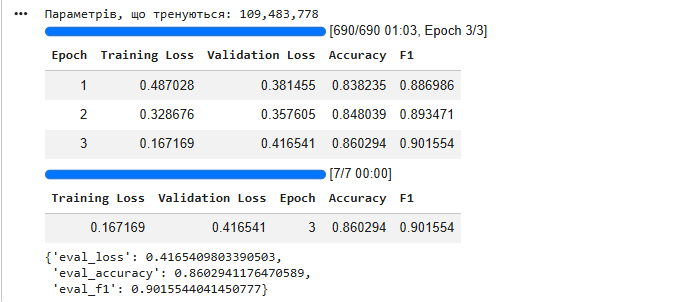


Після збільшення епох:

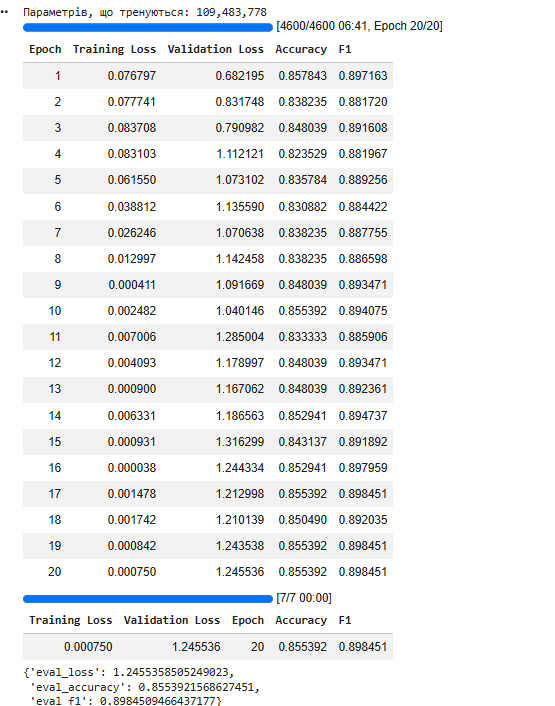


При збільшенні кількості епох до 20 відбулося перенавчання (overfitting): тренувальні втрати (Training Loss) впали майже до нуля (0.000750), тоді як втрати на валідації (Validation Loss) різко зросли (з 0.381455 до 1.245536), а метрики Accuracy та F1 перестали рости й погіршилися порівняно з 3-ю епохою

Причини цього явища:
Малий розмір датасету (лише 3 668 тренувальних прикладів) при величезній кількості параметрів моделі (~110 млн).
   За великої кількості епох модель замість пошуку загальних закономірностей просто «зазубрює» приклади та шум тренувальної вибірки, через що гірше працює на нових даних.Попередньо навченим моделям типу BERT для адаптації під нову задачу (fine-tuning) достатньо 2–4 епох.

10.Що саме перевіряють ці 4 нові пари:
Пасивний/активний стан (server crashed): однаковий зміст, але змінена структура речення — має бути високий відсоток (~90%+).

Антоніми (on time vs late): схожа тема, але протилежний зміст — має бути низький відсоток.

Синоніми (developer/fixed/bug vs programmer/resolved/issue): чистий парафраз — має бути високий відсоток.

Омонім (Apple як компанія vs apple як фрукт): перевірка того, що BERT розуміє контекст слова, а не просто реагує на однакове слово в обох реченнях — має бути низький відсоток.